# Week 2 Day 4 Lab - Agent Swarms

## Working the harder claims in parallel

On Day 1 our agent worked the harder claims one at a time, so each experiment took a few minutes. Today we build a dispatcher that hands the claims to a swarm of claim agents working in parallel.

The dispatcher is a LangGraph graph with no LLM. We build it first with a stand-in for the claim agent. Then we give it the agent with the payout tool from Day 1, and score each run for quality, cost and time.

## 4 parts:

PART 1: A dispatcher with no LLM

PART 2: A swarm of claim agents

PART 3: Scoring the run

PART 4: Five agents or 25

<table style="margin: 0; text-align: left; width:100%">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/stop.png" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#EF476F;">Before you start</h2>
            <span style="color:#EF476F;">This lab calls GPT-6 Luna through OpenRouter and costs a few cents. If you'd rather not spend anything, there's a free version of this lab in <a href="week2day4free.ipynb">week2day4free.ipynb</a>. Part 1 calls no model at all.<br/><br/>
            You'll need the Langfuse keys you set up on Day 1.<br/><br/>
            Please execute each cell and check that you get similar results to mine (the models vary a little from run to run). Some cells have code that isn't about AI, like the charts. It's not important to understand those in detail.
            </span>
        </td>
    </tr>
</table>

In [1]:
import json
import operator
import os
import time
from datetime import datetime
from pathlib import Path
from typing import Annotated, Literal, TypedDict

import pandas as pd
import plotly.express as px
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langfuse import get_client
from langfuse.langchain import CallbackHandler
from langgraph.graph import END, START, StateGraph
from langgraph.types import RetryPolicy, Send
from week2day1_payout import Benefit, Line, Payout, work_out_payout

## Connect to OpenRouter and Langfuse

The keys come from the `.env` file in the `undercover` folder, with the Langfuse keys you added on Day 1.

In [2]:
load_dotenv(override=True)
openrouter_api_key = os.getenv("OPENROUTER_API_KEY")
OPENROUTER_BASE_URL = "https://openrouter.ai/api/v1"

if openrouter_api_key:
    print("OpenRouter API key found")
else:
    print("No OpenRouter API key found. Add OPENROUTER_API_KEY to the .env file")

OpenRouter API key found


In [3]:
langfuse = get_client()

if langfuse.auth_check():
    print("Connected to Langfuse")
else:
    print("No Langfuse keys found. Add them to the .env file")

Connected to Langfuse


## Part 1: A dispatcher with no LLM

### The harder claims

We use the harder claims from Day 1, in `data/evals/harder`, with their policy records and the handlers' decisions.

In [4]:
HARDER = Path("../data/evals/harder")


def load(name):
    """Read one of the JSON files of the harder claims."""
    return json.loads((HARDER / name).read_text(encoding="utf-8"))


claims = {claim["claim_id"]: claim for claim in load("claims.json")}
labels = {decision["claim_id"]: decision for decision in load("decisions.json")}
policies = {policy["policy_id"]: policy for policy in load("policies.json")}
policy_wording = Path("../data/policy_wording.md").read_text(encoding="utf-8")

print(f"{len(claims)} claims, {len(labels)} labels, {len(policies)} policies")

25 claims, 25 labels, 25 policies


### The dispatcher's state

The dispatcher keeps the claims to work and the results that come back. `operator.add` is the reducer on `results`. When several claim agents return results in the same step, LangGraph adds their lists together.

In [5]:
class Dispatch(TypedDict):
    """What the dispatcher keeps for one run."""

    claims: list[str]
    results: Annotated[list, operator.add]

### Listing the claims and fanning out

`list_claims` picks the claims to work. In the product it will ask the backend for the claims waiting in the queue.

`fan_out` is a conditional edge that returns one `Send` for each claim. A `Send` names the node to run and the input to give it, so `work_claim` runs once for every claim.

In [6]:
def list_claims(state: Dispatch):
    """The claims to work in this run."""
    return {"claims": list(claims)}


def fan_out(state: Dispatch):
    """Send each claim to a claim agent."""
    return [Send("work_claim", claim_id) for claim_id in state["claims"]]

### A stand-in for the claim agent

Before we spend anything on a model, we give the dispatcher a stand-in that takes one second to work a claim. It records when it started and finished, so we can see how the claims overlap.

In [7]:
def stand_in(claim_id):
    """Pretend to work a claim for one second."""
    started = datetime.now()
    time.sleep(1)
    return {"results": [{"claim_id": claim_id, "started": started, "finished": datetime.now()}]}

### Building the graph

The stand-in goes in as the `work_claim` node. The list of nodes in `add_conditional_edges` tells LangGraph where `fan_out` can send, so it can draw the graph.

In [8]:
builder = StateGraph(Dispatch)
builder.add_node("list_claims", list_claims)
builder.add_node("work_claim", stand_in)
builder.add_edge(START, "list_claims")
builder.add_conditional_edges("list_claims", fan_out, ["work_claim"])
builder.add_edge("work_claim", END)
dispatcher = builder.compile()

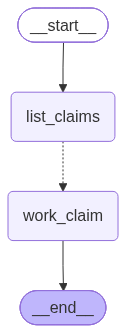

In [9]:
dispatcher

The dashed line is the conditional edge. There's no model in this graph. LangGraph is a good way to run any workflow with parallel steps, retries and saved state, whether or not it has agents in it.

### Capping the swarm

`max_concurrency` in the config caps how many nodes run at once. On Day 1, Langfuse's `run_experiment` had `max_concurrency=1`, so it worked one claim at a time. Here we try 1, 5 and 25 at once.

In [10]:
result = dispatcher.invoke({}, {"max_concurrency": 1})
table = pd.DataFrame(result["results"])
seconds = (table["finished"].max() - table["started"].min()).total_seconds()
print(f"1 agent at once: {len(table)} claims in {seconds:.1f} seconds")

1 agent at once: 25 claims in 25.0 seconds


In [11]:
result = dispatcher.invoke({}, {"max_concurrency": 5})
table = pd.DataFrame(result["results"])
seconds = (table["finished"].max() - table["started"].min()).total_seconds()
print(f"5 agents at once: {len(table)} claims in {seconds:.1f} seconds")

5 agents at once: 25 claims in 5.0 seconds


In [12]:
result = dispatcher.invoke({}, {"max_concurrency": 25})
table = pd.DataFrame(result["results"])
seconds = (table["finished"].max() - table["started"].min()).total_seconds()
print(f"25 agents at once: {len(table)} claims in {seconds:.1f} seconds")

25 agents at once: 25 claims in 1.0 seconds


There are never more than N claims running at once. Here's the run with 5 at once. Each bar is a claim, from when it started to when it finished.

In [13]:
def show_timeline(results, title):
    """Draw each claim as a bar from when it started to when it finished."""
    fig = px.timeline(pd.DataFrame(results), x_start="started", x_end="finished", y="claim_id", title=title)
    fig.update_yaxes(autorange="reversed")
    fig.show()


result = dispatcher.invoke({}, {"max_concurrency": 5})
show_timeline(result["results"], "The stand-in, 5 at once")

### Retries

When many agents call a model at once, some calls get a 429 ("Too Many Requests") or time out. Without a retry, one failed claim stops the whole run. A `RetryPolicy` on a node runs it again after a short wait, and waits longer after each failure.

This stand-in fails the first time it works CLM-1207, as if the model had sent back a 429.

In [14]:
tries = {}


def flaky_stand_in(claim_id):
    """The stand-in, failing the first time it works CLM-1207."""
    tries[claim_id] = tries.get(claim_id, 0) + 1
    if claim_id == "CLM-1207" and tries[claim_id] == 1:
        raise Exception("429 Too Many Requests")
    return stand_in(claim_id)

In [15]:
builder = StateGraph(Dispatch)
builder.add_node("list_claims", list_claims)
builder.add_node("work_claim", flaky_stand_in, retry_policy=RetryPolicy(max_attempts=3))
builder.add_edge(START, "list_claims")
builder.add_conditional_edges("list_claims", fan_out, ["work_claim"])
builder.add_edge("work_claim", END)
flaky_dispatcher = builder.compile()

result = flaky_dispatcher.invoke({}, {"max_concurrency": 25})
print(f"{len(result['results'])} claims done. CLM-1207 took {tries['CLM-1207']} tries.")
show_timeline(result["results"], "The flaky stand-in, 25 at once")

25 claims done. CLM-1207 took 2 tries.


CLM-1207 started again after a short wait, and every claim was done.

## Part 2: A swarm of claim agents

### The claim agent

The claim agent is Day 1's agent with the payout tool: the same instructions, prompt and tools, on GPT-6 Luna with its reasoning at `low`, as on Days 2 and 3.

In [16]:
INSTRUCTIONS = """You are a claims handler at UnderCover Travel Insurance.
Decide the claim you are given, using the policy wording below and the customer's policy record.

Choose one decision:
- approve: the wording covers the claim and the required documents are attached. Work out the payout using section 10.
- decline: the wording does not cover the claim.
- refer: a colleague needs to look at it, because a required document is missing, or the story and the documents disagree, or the wording does not settle the question.

Use your tools to record your decision.
Use the payout tool to work out the payout on an approved claim, and record the payout it returns.
"""


def make_user_prompt(claim):
    """The customer's policy record and the claim, as JSON."""
    policy = policies[claim["policy_id"]]
    return f"""# Policy record

{json.dumps(policy, indent=2)}

# Claim

{json.dumps(claim, indent=2)}
"""

As on Day 1, a decision can't be changed once it's recorded, and that keeps retries safe. If a claim agent fails after recording its decision, the `RetryPolicy` works the claim again and the agent's second decision is refused. UnderCover's backend refuses a second decision or payment in the same way.

In [17]:
recorded = {}


@tool(parse_docstring=True)
def record_decision(claim_id: str, rationale: str, decision: Literal["approve", "decline", "refer"], payout: float) -> str:
    """Record the decision on a claim in the claims system.

    Args:
        claim_id: The claim's id
        rationale: 2-3 sentences to explain the decision along with the relevant section of the policy
        decision: The decision on the claim
        payout: The amount to pay in US dollars, or 0 for a decline or a referral
    """
    if claim_id in recorded:
        return f"A decision is already recorded on {claim_id}, and decisions are final"
    if decision == "approve" and payout <= 0:
        return "An approval needs a payout above zero"
    recorded[claim_id] = {"decision": decision, "payout": payout, "rationale": rationale}
    return f"Recorded {decision} on {claim_id}"

In [18]:
@tool(parse_docstring=True)
def calculate_payout(policy_id: str, benefit: Benefit, lines: list[Line], paid_by_others: float = 0.0) -> Payout:
    """Work out the payout on an approved claim with UnderCover's payout rules.

    Args:
        policy_id: The customer's policy id
        benefit: The benefit the claim is paid under
        lines: The covered items and expenses, one for each line of the claim, with any excluded ones left out. A pair or a set counts as one item
        paid_by_others: Anything a carrier, hotel or other party has paid or refunded for the same loss

    Returns:
        The calculation, the payout and whether it needs sign-off
    """
    return work_out_payout(policies[policy_id], benefit, lines, paid_by_others)

In [19]:
luna = ChatOpenAI(model="openai/gpt-6-luna", base_url=OPENROUTER_BASE_URL, api_key=openrouter_api_key, reasoning_effort="low", timeout=120, max_retries=5)

payout_agent = create_agent(model=luna, tools=[record_decision, calculate_payout], system_prompt=f"{INSTRUCTIONS}\n{policy_wording}\n")

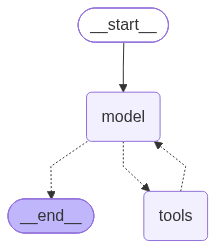

In [20]:
payout_agent

### The work_claim node

`work_claim` runs the agent on one claim. It returns what the agent recorded, with the cost of its model calls and when it started and finished. If the agent finishes without recording a decision, the claim would go to a handler, so we count it as a referral.

A node is still a Python function, so we can try it on one claim before the swarm does. Here's the burglary in Rome.

In [21]:
def work_claim(claim_id):
    """Run the claim agent on one claim and return its result."""
    started = datetime.now()
    result = payout_agent.invoke({"messages": [{"role": "user", "content": make_user_prompt(claims[claim_id])}]})
    answer = recorded.get(claim_id, {"decision": "refer", "payout": 0.0, "rationale": "Nothing recorded"})
    cost = sum(message.response_metadata["token_usage"]["cost"] for message in result["messages"] if message.type == "ai")
    print(f"{claim_id}: {answer['decision']} ${answer['payout']:,.2f}")
    return {"results": [{"claim_id": claim_id, **answer, "cost": cost, "started": started, "finished": datetime.now()}]}

In [22]:
work_claim("CLM-1203")

CLM-1203: approve $2,910.44


{'results': [{'claim_id': 'CLM-1203',
   'decision': 'approve',
   'payout': 2910.44,
   'rationale': 'Approve under section 5: the theft occurred during the covered trip and was reported to local police immediately, with the police report and proof of the other insurer’s payment attached. Section 10 limits eligible items, subtracts the $2,250 paid by the apartment owner’s insurer, and the returned calculation is $2,910.44 (including the policy’s applicable item limits and $100 aggregate cash cap).',
   'cost': 0.001014935,
   'started': datetime.datetime(2026, 10, 26, 14, 26, 54, 933556),
   'finished': datetime.datetime(2026, 10, 26, 14, 27, 5, 817689)}]}

### The swarm

The same graph, with `work_claim` in place of the stand-in and a `RetryPolicy`. `ChatOpenAI` already retries a single call up to 5 times with `max_retries=5`, and the `RetryPolicy` works the whole claim again if it still fails.

In [23]:
builder = StateGraph(Dispatch)
builder.add_node("list_claims", list_claims)
builder.add_node("work_claim", work_claim, retry_policy=RetryPolicy(max_attempts=3))
builder.add_edge(START, "list_claims")
builder.add_conditional_edges("list_claims", fan_out, ["work_claim"])
builder.add_edge("work_claim", END)
dispatcher = builder.compile()

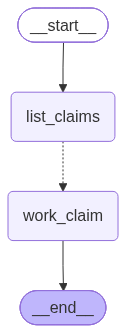

In [24]:
dispatcher

By default the swarm works all 25 claims. If you'd like a quicker run, set `TINY = True` to keep 5 of them.

In [25]:
TINY = False

if TINY:
    claims = {claim_id: claim for claim_id, claim in claims.items() if labels[claim_id]["tiny"]}

print(f"The swarm works {len(claims)} claims")

The swarm works 25 claims


### Five claim agents at once

We pass Langfuse's `CallbackHandler` in the config, as on Day 1. LangGraph hands the config on to every node, so each claim agent's model calls and tool calls go into one trace for the whole run. `run_name` names the trace.

In [26]:
langfuse_handler = CallbackHandler()

recorded.clear()
result = dispatcher.invoke({}, {"max_concurrency": 5, "callbacks": [langfuse_handler], "run_name": "Swarm of 5"})
swarm_of_5 = result["results"]

CLM-1203: approve $2,310.44


CLM-1201: approve $553.28


CLM-1202: approve $2,048.44
CLM-1205: approve $1,021.14


CLM-1204: approve $4,787.25


CLM-1206: approve $1,450.01


...

CLM-1221: decline $0.00


CLM-1222: refer $0.00


CLM-1224: refer $0.00


CLM-1225: refer $0.00


CLM-1218: approve $4,427.95
CLM-1223: refer $0.00


In [27]:
show_timeline(swarm_of_5, "The claim agents, 5 at once")

Each claim takes a different time, and a new claim starts as soon as one of the five finishes.

Now open **Tracing** in Langfuse. With the filter `Is Root Observation = true`, there's one row for each run. Open the trace called `Swarm of 5`. The timeline view shows the claim agents working side by side.

## Part 3: Scoring the run

We score the run with Day 1's measures, and add cost and time.

- `decision_accuracy`, `accuracy`, `cost_of_mistakes` and `straight_through` are Day 1's measures.
- `llm_cost` is what the run's model calls cost.
- `seconds` is the time from the first claim starting to the last claim finishing.
- `slowest_claim` is the time the slowest claim took, and `seconds_per_claim` is the average.

In [28]:
WRONGFUL_DECLINE = 1500
NEEDLESS_REFERRAL = 50


def is_right(answer, expected):
    """True when the decision matches the handler's and the payout is within a dollar."""
    return answer["decision"] == expected["decision"] and abs(answer["payout"] - expected["payout"]) <= 1


def mistake_cost(answer, expected):
    """What the agent's answer costs UnderCover, against the handler's decision."""
    if answer["decision"] == expected["decision"]:
        return abs(answer["payout"] - expected["payout"]) if answer["decision"] == "approve" else 0
    if answer["decision"] == "decline":
        return WRONGFUL_DECLINE
    if answer["decision"] == "approve":
        return answer["payout"]
    return NEEDLESS_REFERRAL

In [29]:
def score_table(results):
    """One row for each claim in a run: the agent's answer beside the handler's, with the scores."""
    rows = []
    for answer in results:
        expected = labels[answer["claim_id"]]
        rows.append({
            "claim_id": answer["claim_id"],
            "handler": expected["decision"],
            "agent": answer["decision"],
            "handler_payout": expected["payout"],
            "agent_payout": answer["payout"],
            "right": is_right(answer, expected),
            "mistake_cost": mistake_cost(answer, expected),
            "llm_cost": answer["cost"],
            "started": answer["started"],
            "finished": answer["finished"],
            "seconds": (answer["finished"] - answer["started"]).total_seconds(),
            "rationale": answer["rationale"],
        })
    return pd.DataFrame(rows).sort_values("claim_id")


def run_scores(table):
    """The scores for a whole run: quality, cost and time."""
    return {
        "decision_accuracy": (table["agent"] == table["handler"]).mean(),
        "accuracy": table["right"].mean(),
        "cost_of_mistakes": table["mistake_cost"].sum(),
        "straight_through": (table["agent"] != "refer").mean(),
        "llm_cost": table["llm_cost"].sum(),
        "seconds": (table["finished"].max() - table["started"].min()).total_seconds(),
        "slowest_claim": table["seconds"].max(),
        "seconds_per_claim": table["seconds"].mean(),
    }

In [30]:
table_5 = score_table(swarm_of_5)
scores_5 = run_scores(table_5)

pd.Series(scores_5).round(3)

decision_accuracy       0.920
accuracy                0.840
cost_of_mistakes     1249.000
straight_through        0.680
llm_cost                0.013
seconds                44.493
slowest_claim          16.936
seconds_per_claim       8.586
dtype: float64

Here are the claims it got wrong, with the agent's rationale.

In [31]:
table_5[~table_5["right"]]

,claim_id,handler,agent,handler_payout,agent_payout,right,mistake_cost,llm_cost,started,finished,seconds,rationale
2,CLM-1203,approve,approve,2910.44,2310.44,False,600.0,0.000529,2026-10-26 14:27:05.978219,2026-10-26 14:27:13.755315,7.777096,Approve under section 5: the theft occurred du...
8,CLM-1209,approve,refer,4180.15,0.00,False,50.0,0.000754,2026-10-26 14:27:15.901158,2026-10-26 14:27:27.614388,11.713230,Refer for review under sections 7 and 8: rafti...
15,CLM-1216,approve,approve,1677.90,1128.90,False,549.0,0.000534,2026-10-26 14:27:27.943601,2026-10-26 14:27:37.504008,9.560407,Approve under section 5: the police report doc...
19,CLM-1220,decline,refer,0.00,0.00,False,50.0,0.000252,2026-10-26 14:27:37.505513,2026-10-26 14:27:41.435400,3.929887,Refer for review under section 7: the medical ...


### Scores in Langfuse

`create_score` adds a score to a trace. The handler's `last_trace_id` is the trace it wrote last, which is the run we just scored.

In [32]:
def send_scores(trace_id, scores):
    """Add a run's scores to its trace in Langfuse."""
    for name, value in scores.items():
        langfuse.create_score(trace_id=trace_id, name=name, value=float(value))


send_scores(langfuse_handler.last_trace_id, scores_5)

In Langfuse, the scores appear on the `Swarm of 5` trace, and as columns in the list of traces.

## Part 4: Five agents or 25

Now the same claims with 25 claim agents, so every claim starts at once.

In [33]:
recorded.clear()
result = dispatcher.invoke({}, {"max_concurrency": 25, "callbacks": [langfuse_handler], "run_name": "Swarm of 25"})
swarm_of_25 = result["results"]

table_25 = score_table(swarm_of_25)
scores_25 = run_scores(table_25)
send_scores(langfuse_handler.last_trace_id, scores_25)

CLM-1211: refer $0.00


CLM-1210: decline $0.00
CLM-1221: decline $0.00


CLM-1212: refer $0.00
CLM-1225: refer $0.00


CLM-1220: refer $0.00


CLM-1222: refer $0.00


...

CLM-1203: approve $2,910.44
CLM-1208: approve $3,668.80
CLM-1217: approve $1,335.90


CLM-1216: approve $1,677.90
CLM-1206: approve $1,450.01


CLM-1215: approve $1,415.78


CLM-1201: approve $553.28
CLM-1209: approve $4,180.15


CLM-1218: approve $4,927.55


In [34]:
show_timeline(swarm_of_25, "The claim agents, 25 at once")

### The scoreboard

In [35]:
pd.DataFrame([scores_5, scores_25], index=["5 at once", "25 at once"]).round(3)

,decision_accuracy,accuracy,cost_of_mistakes,straight_through,llm_cost,seconds,slowest_claim,seconds_per_claim
5 at once,0.92,0.84,1249.0,0.68,0.013,44.493,16.936,8.586
25 at once,0.96,0.92,549.6,0.72,0.010,14.454,14.338,8.148


What the scoreboard shows:

- **The swarm saves time.** One at a time, as on Day 1, the run would take about 25 times `seconds_per_claim`, which is over two minutes. With 5 at once it takes about a fifth of that.
- **The slowest claim sets the clock.** With 25 at once, the run takes about as long as its slowest claim.
- **The cost per claim stays about the same.** Each claim makes the same model calls at any N. The second run can cost a little less, because OpenAI's prompt cache already holds the policy wording from the first.
- **Accuracy comes from the agent.** It moves from run to run as it did on Day 1, and N doesn't change it.
- **The limits are outside the agent.** With 25 at once, every claim agent calls OpenRouter at the same moment. A paid account handles that, but OpenRouter's free models allow 20 requests a minute, which is why the free version runs 3 at once. In the product, each claim agent also uses connections to Supabase, and the free plan's session pooler allows 15 at once.

In Langfuse, open the `Swarm of 25` trace and compare its timeline with the one for `Swarm of 5`.

<table style="margin: 0; text-align: left; width:100%">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/info.png" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#118AB2;">One thread here, a thread for each claim in the product</h2>
            <span style="color:#118AB2;">In this lab the whole swarm runs as one graph on one thread, and LangGraph collects every claim's result into one list. That works because nobody waits on a handler here.<br/><br/>
            In UnderCover's product, a claim over the limit can wait days for a sign-off, so each claim keeps its own thread, as on Day 3, and the dispatcher only starts them. On one shared thread, one <code>interrupt()</code> would pause the whole dispatch, two sign-offs at once would race to resume the same checkpoint, and recovering from a crash would mean recovering the whole dispatch. Langfuse would also get one very long trace, so the product tags each claim's trace with the dispatch run's id instead.
            </span>
        </td>
    </tr>
</table>

<table style="margin: 0; text-align: left; width:100%">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/business.png" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#118AB2;">Commercial implications</h2>
            <span style="color:#118AB2;">Work often arrives in batches: a morning's claims, a month's invoices or a backlog of support tickets. A swarm of agents can work a batch in about the time of its slowest item, at the same cost per item. The limits are usually in the systems around the agents, such as the model provider's rate limits, the database's connections and the people who check the results.<br/><br/>
            Consider which batch jobs in your business would gain most from finishing in minutes.
            </span>
        </td>
    </tr>
</table>

<table style="margin: 0; text-align: left; width:100%">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/exercise.png" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#EF476F;">Your assignment</h2>
            <span style="color:#EF476F;">Challenge: the dispatcher fans out to the claim agents but never comes back together. Add a <code>score_run</code> node after <code>work_claim</code> that scores the whole run and puts the scores in the state. LangGraph runs it once, after every claim agent has finished. Try it with the stand-in first.<br/><br/>
            Stretch challenge: compile the dispatcher with Day 3's <code>PostgresSaver</code> and run it on a thread of its own. Restart the kernel while the claim agents are working, then run the dispatcher again on the same thread with <code>invoke(None, config)</code>. Which claims does LangGraph work again?<br/><br/>
            I'd love it if you would consider making a PR with your version of the lab in the <code>community_contributions</code> folder. There are instructions on making a PR at <a href="https://edwarddonner.com/pr">edwarddonner.com/pr</a>.
            </span>
        </td>
    </tr>
</table>

## Clearing out Langfuse

By now your Langfuse project holds hundreds of traces. If you'd like to start Day 5 with an empty project, set `CLEAR_LANGFUSE = True` in the cell after next and run it. It deletes every trace in the project with its observations and scores. There's no undo.

Langfuse keeps a trace as the observations that share its id, so we list every observation and collect the trace ids. Langfuse deletes the traces in the background, usually within 15 minutes. The free Hobby plan allows 50 delete requests a day. Each request here deletes up to 1,000 traces. Scores for a whole experiment, like Day 1's kappa, aren't on a trace and stay in the project.

In [36]:
def all_trace_ids():
    """The id of every trace in the Langfuse project."""
    trace_ids = set()
    cursor = None
    while True:
        page = langfuse.api.observations.get_many(fields="core", limit=1000, cursor=cursor)
        trace_ids.update(observation.trace_id for observation in page.data)
        cursor = page.meta.cursor
        if not cursor:
            return sorted(trace_ids)

In [37]:
CLEAR_LANGFUSE = False

langfuse.flush()
trace_ids = all_trace_ids()
print(f"Your Langfuse project has {len(trace_ids)} traces")

if CLEAR_LANGFUSE:
    for start in range(0, len(trace_ids), 1000):
        langfuse.api.trace.delete_multiple(trace_ids=trace_ids[start:start + 1000])
    print(f"Asked Langfuse to delete {len(trace_ids)} traces")

Your Langfuse project has 547 traces
